# Analysing SES, race and relationship stability

**Inputs:** `hcmst2017_clean.csv` (01), `hcmst2017_person_period.csv` (02), `hcmst2017_race.csv` (03)

**Research question:** To what extent does the association between socioeconomic status and
relationship stability vary across racial groups in the US?

**Hypotheses**:
- **H1:** Higher household income is associated with a lower risk of breaking up.
- **H2:** Respondents who earn more than their partner have a higher risk of breaking up (CLalt).
- **H3:** The protective association of income is weaker for Black and Hispanic couples than for White couples.

**Method:** Discrete-time event history analysis. Logistic regression on person-period data (one row
per couple per survey gap), with standard errors clustered by respondent. Main analysis: same-race
White, Black and Hispanic couples. Robustness check: all couples.

## 1. Setting up

Install the packages used in this notebook: `statsmodels` for the regression models and `plotnine`
for charts.

In [ ]:
# %pip install statsmodels plotnine


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Loading and joining the data

Load the three processed files and join them by respondent ID (`caseid_new`), so each person-period
row carries that couple's income, controls and race.

In [5]:
from plotnine import ggplot, aes, geom_line, geom_ribbon, geom_point, geom_text, labs, theme, theme_minimal, scale_x_continuous, scale_y_continuous

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

clean = pd.read_csv("../data/processed/hcmst2017_clean.csv", low_memory=False)
race = pd.read_csv("../data/processed/hcmst2017_race.csv")
pp = pd.read_csv("../data/processed/hcmst2017_person_period.csv")

print("Clean:", clean.shape, "| Race:", race.shape, "| Person-period:", pp.shape)

# Attach race to the cleaned data, then attach both to each person-period row
couples = clean.merge(race, on="caseid_new", how="left")
df = pp.merge(couples, on="caseid_new", how="left")

print("Joined:", df.shape)

Clean: (2862, 730) | Race: (2862, 4) | Person-period: (2883, 3)
Joined: (2883, 735)


## 3. Building the analysis sample

**Controls** (all measured in 2017): married vs unmarried, relationship length in years, respondent
age, same-sex couple, and children under 18 in the household. Relationship length is negative for a
handful of couples who reported a start date just after the interview; these are set to 0.

**Main sample:** same-race White, Black and Hispanic couples with no missing values on income or
the controls.

In [3]:
# Control variables
df["married"] = (df["w1_partnership_status"] == "married").astype(int)
df["same_sex"] = np.where(df["w1_same_sex_couple"].isna(), np.nan,
                          (df["w1_same_sex_couple"] == "same_sex_couple").astype(int))
df["children"] = (df[["w1_PPT01", "w1_PPT25", "w1_PPT612", "w1_PPT1317"]].sum(axis=1) > 0).astype(int)
df["duration"] = df["w1_relate_duration_in2017_years"].clip(lower=0)
df["age"] = df["w1_ppage"]

# Main sample: same-race White, Black and Hispanic couples, no missing values
needed = ["income_ordinal", "married", "same_sex", "children", "duration", "age"]
main = df[(df["same_race"] == True) & df["race_respondent"].isin(["White", "Black", "Hispanic"])]
main = main.dropna(subset=needed).copy()

# Summary by race: rows, couples, breakups
sample_summary = main.groupby("race_respondent").agg(
    rows=("broke_up", "size"),
    couples=("caseid_new", "nunique"),
    breakups=("broke_up", "sum"),
).reindex(["White", "Black", "Hispanic"])
sample_summary.to_csv("../output/tables/analysis_sample_by_race.csv")

print("Main sample:", len(main), "rows |", main["caseid_new"].nunique(), "couples |", main["broke_up"].sum(), "breakups")
sample_summary

Main sample: 2191 rows | 1334 couples | 158 breakups


/var/folders/tk/j75m2rk91ll9tl_rymw764qh0000gn/T/ipykernel_22413/3519210248.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["married"] = (df["w1_partnership_status"] == "married").astype(int)
/var/folders/tk/j75m2rk91ll9tl_rymw764qh0000gn/T/ipykernel_22413/3519210248.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["same_sex"] = np.where(df["w1_same_sex_couple"].isna(), np.nan,
/var/folders/tk/j75m2rk91ll9tl_rymw764qh0000gn/T/ipykernel_22413/3519210248.py:5: PerformanceWarning: DataFrame is highly fragmented.  This 

,rows,couples,breakups
race_respondent,,,
White,1924,1157,113
Black,125,83,24
Hispanic,142,94,21


## 4. Share of couples still together over time

Share of same-race couples still together at each survey, by race. Calculated from the breakup rate
in each gap: still together in 2020 = 1 − 2017–2020 breakup rate; still together in 2022 = 2020
share × (1 − 2020–2022 breakup rate). Couples who skipped the 2020 survey are not included here.

In [4]:
from plotnine import geom_point, geom_text, scale_x_continuous

rows = []
for race in ["White", "Black", "Hispanic"]:
    g = main[main["race_respondent"] == race]
    s2020 = 1 - g.loc[g["period"] == "2017-2020", "broke_up"].mean()
    s2022 = s2020 * (1 - g.loc[g["period"] == "2020-2022", "broke_up"].mean())
    label = f"{race} (n = {g['caseid_new'].nunique()})"
    for year, share in [(2017, 1.0), (2020, s2020), (2022, s2022)]:
        rows.append({"year": year, "still_together": share, "race": label})

still = pd.DataFrame(rows)
still["label"] = (still["still_together"] * 100).round().astype(int).astype(str) + "%"
still.to_csv("../output/tables/still_together_by_race.csv", index=False)

chart2 = (
    ggplot(still, aes("year", "still_together", colour="race"))
    + geom_line(size=1.2)
    + geom_point(size=3)
    + geom_text(aes(label="label"), nudge_x=0.45, size=9, show_legend=False)
    + scale_x_continuous(breaks=[2017, 2020, 2022])
    + scale_y_continuous(limits=(0.5, 1), labels=lambda v: [f"{x:.0%}" for x in v])
    + labs(x="Survey year", y="Share of couples still together",
           colour="Same-race couples", title="Share of couples still together, 2017–2022")
    + theme_minimal()
)
chart2.save("../output/figures/still_together_by_race.png", width=8, height=5, dpi=200)
chart2

NameError: name 'ggplot' is not defined

## 5. Model 1: income only

Logistic regression of breaking up on household income (1–21 scale), with the survey gap included
because baseline breakup rates differ between gaps. Standard errors are clustered by respondent.

In [ ]:
m1 = smf.logit("broke_up ~ income_ordinal + C(period)", data=main).fit(
    disp=False, cov_type="cluster", cov_kwds={"groups": main["caseid_new"]}
)
print(m1.summary())

                           Logit Regression Results                           
Dep. Variable:               broke_up   No. Observations:                 2191
Model:                          Logit   Df Residuals:                     2187
Method:                           MLE   Df Model:                            3
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.1066
Time:                        17:38:59   Log-Likelihood:                -507.11
converged:                       True   LL-Null:                       -567.62
Covariance Type:              cluster   LLR p-value:                 4.623e-26
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0.3979      0.248     -1.602      0.109      -0.885       0.089
C(period)[T.2017-2022]     0.5069      0.375      1.352      0.176      -0.228       1.242
C(pe

## 6. Model 2: adding race and controls

Adds race (Black and Hispanic, each compared with White couples) and the controls: married,
relationship length, age, same-sex couple, and children in the household. This tests whether the
income association holds when comparing otherwise similar couples.

In [ ]:
# Race as yes/no columns (White = comparison group)
main["black"] = (main["race_respondent"] == "Black").astype(int)
main["hispanic"] = (main["race_respondent"] == "Hispanic").astype(int)

controls = "married + duration + age + same_sex + children + C(period)"

m2 = smf.logit(f"broke_up ~ income_ordinal + black + hispanic + {controls}", data=main).fit(
    disp=False, cov_type="cluster", cov_kwds={"groups": main["caseid_new"]}
)
print(m2.summary())

                           Logit Regression Results                           
Dep. Variable:               broke_up   No. Observations:                 2191
Model:                          Logit   Df Residuals:                     2180
Method:                           MLE   Df Model:                           10
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3174
Time:                        17:38:59   Log-Likelihood:                -387.49
converged:                       True   LL-Null:                       -567.62
Covariance Type:              cluster   LLR p-value:                 2.623e-71
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0.2684      0.422      0.636      0.525      -0.558       1.095
C(period)[T.2017-2022]     0.4962      0.399      1.245      0.213      -0.285       1.278
C(pe

## 7. How much of income's effect is explained by the controls?

Average predicted chance of breaking up (2017–2020) at each income level, from Model 1 (income only)
and Model 2 (adding race and controls). For each income level, every couple is assigned that income
while keeping their other characteristics, and the predicted chances are averaged. The gap between
the two lines shows how much of income's apparent effect reflects marriage, relationship length and
the other controls.

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 8 x 5 in image.
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ../output/figures/income_effect_before_after_controls.png


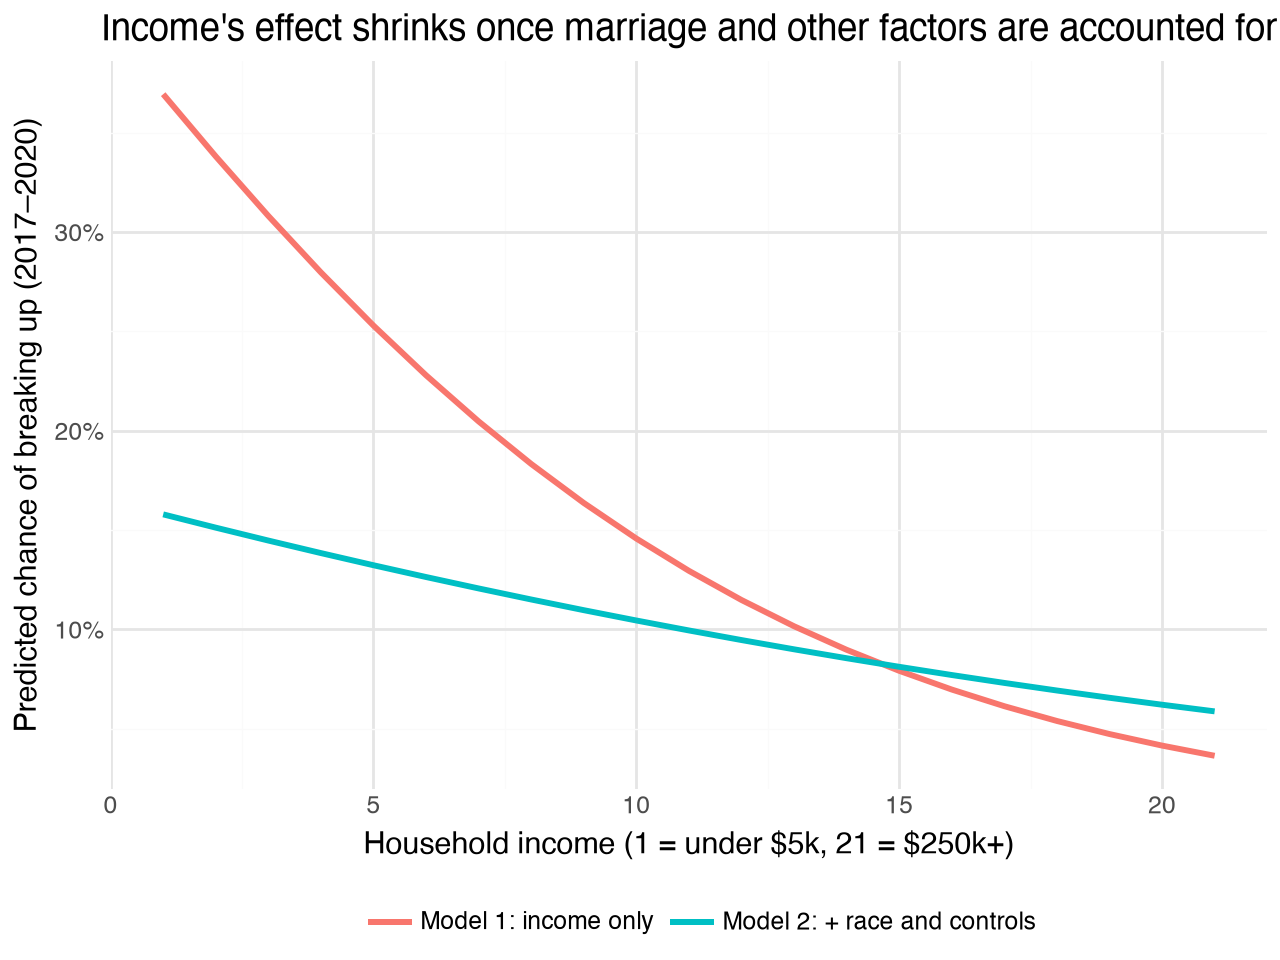

In [ ]:
from plotnine import theme
rows = []
for inc in range(1, 22):
    t = main.copy() 
    t["income_ordinal"] = inc
    t["period"] = "2017-2020"
    rows.append({"income_ordinal": inc, "model": "Model 1: income only", "predicted": m1.predict(t).mean()})
    rows.append({"income_ordinal": inc, "model": "Model 2: + race and controls", "predicted": m2.predict(t).mean()})

adjust = pd.DataFrame(rows)
adjust.to_csv("../output/tables/income_effect_before_after_controls.csv", index=False)

chart3 = (
    ggplot(adjust, aes("income_ordinal", "predicted", colour="model"))
    + geom_line(size=1.2)
    + scale_y_continuous(labels=lambda v: [f"{x:.0%}" for x in v])
    + labs(x="Household income (1 = under \\$5k, 21 = \\$250k+)",
           y="Predicted chance of breaking up (2017–2020)",
           colour="",
           title="Income's effect shrinks once marriage and other factors are accounted for")
    + theme_minimal()
    + theme(legend_position="bottom")
)
chart3.save("../output/figures/income_effect_before_after_controls.png", width=8, height=5, dpi=200)
chart3


## 8. Model 3: does income matter differently by race?

Adds interactions between income and race, letting the income association differ for Black and
Hispanic couples compared with White couples. This directly tests our research question (H3).
We then test whether the two interaction terms together improve the model: a likelihood-ratio
test (Model 2 vs Model 3), and a Wald test that also accounts for the clustering.

In [ ]:
from scipy.stats import chi2

m3 = smf.logit(f"broke_up ~ income_ordinal * black + income_ordinal * hispanic + {controls}", data=main).fit(
    disp=False, cov_type="cluster", cov_kwds={"groups": main["caseid_new"]}
)
print(m3.summary())

# Do the two interaction terms improve the model?
lr = 2 * (m3.llf - m2.llf)
print(f"\nLikelihood-ratio test: LR = {lr:.2f}, p = {chi2.sf(lr, 2):.3f}")
print(m3.wald_test("income_ordinal:black = 0, income_ordinal:hispanic = 0", scalar=True))

                           Logit Regression Results                           
Dep. Variable:               broke_up   No. Observations:                 2191
Model:                          Logit   Df Residuals:                     2178
Method:                           MLE   Df Model:                           12
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3187
Time:                        17:38:59   Log-Likelihood:                -386.71
converged:                       True   LL-Null:                       -567.62
Covariance Type:              cluster   LLR p-value:                 4.449e-70
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                   0.2904      0.436      0.666      0.505      -0.564       1.144
C(period)[T.2017-2022]      0.4954      0.394      1.257      0.209      -0.277       1.268


## 9. Predicted chance of breaking up, by income and race

Predicted probability of breaking up during the 2017–2020 gap, from Model 3, for a couple with
average values on the controls. Shaded bands are 95% confidence intervals, so wider bands mean
less certainty.

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 8 x 5 in image.
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ../output/figures/predicted_breakup_by_income_race.png


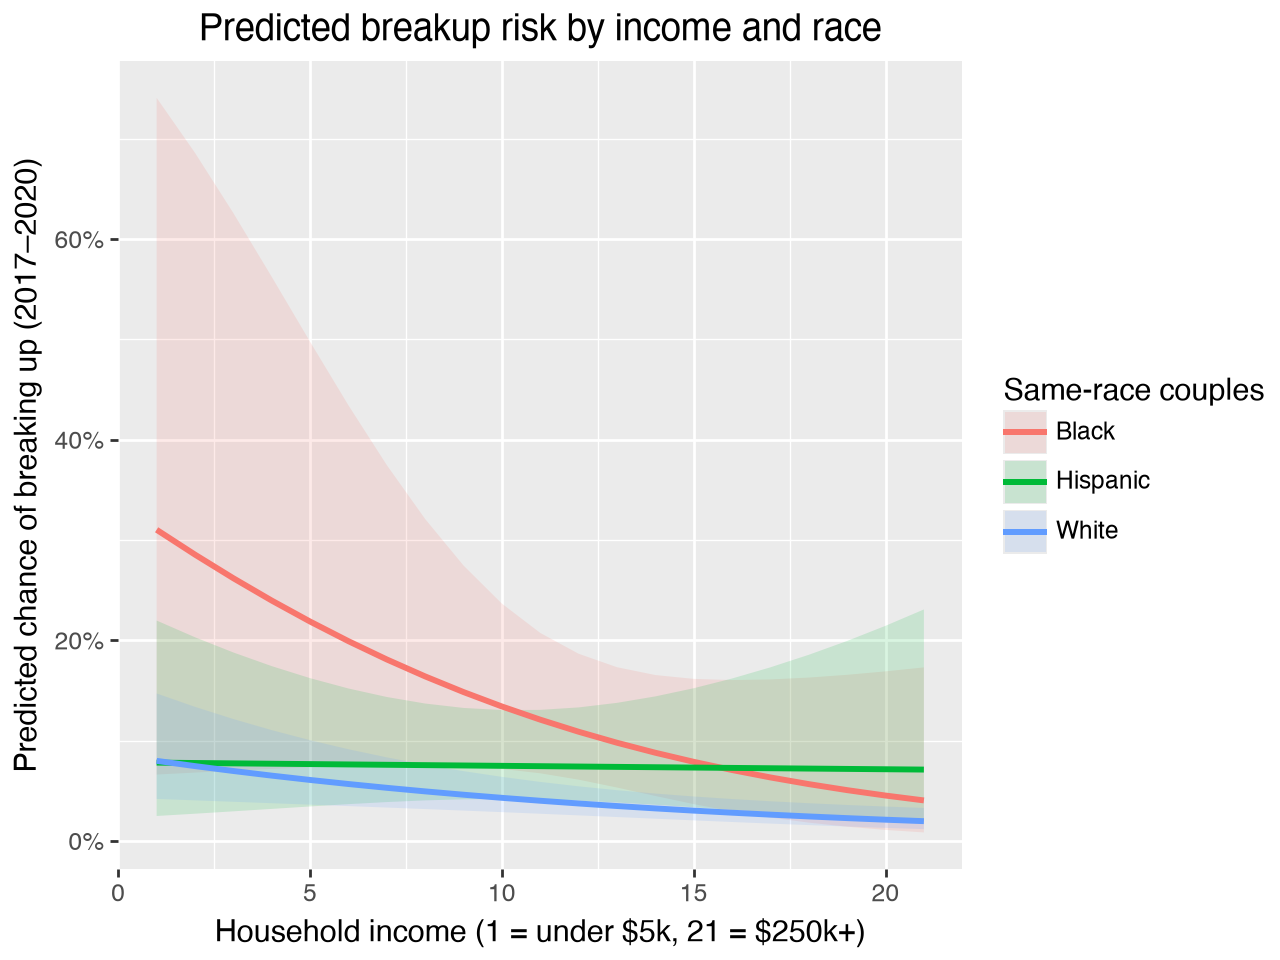

In [ ]:
from plotnine import ggplot, aes, geom_line, geom_ribbon, labs, theme_minimal, scale_y_continuous

# A "typical" couple: average controls, 2017-2020 gap
typical = {c: main[c].mean() for c in ["married", "duration", "age", "same_sex", "children"]}

grid = pd.DataFrame(
    [{"income_ordinal": inc, "race": race, **typical, "period": "2017-2020"}
     for race in ["White", "Black", "Hispanic"] for inc in range(1, 22)]
)
grid["black"] = (grid["race"] == "Black").astype(int)
grid["hispanic"] = (grid["race"] == "Hispanic").astype(int)

# Predicted chance + 95% confidence interval
pred = m3.get_prediction(grid).summary_frame(alpha=0.05)
grid["predicted"] = pred["predicted"].values
grid["lower"] = pred["ci_lower"].values
grid["upper"] = pred["ci_upper"].values
grid.to_csv("../output/tables/predicted_breakup_by_income_race.csv", index=False)

chart = (
    ggplot(grid, aes("income_ordinal", "predicted", colour="race", fill="race"))
    + geom_ribbon(aes(ymin="lower", ymax="upper"), alpha=0.15, colour="none")
    + geom_line(size=1.2)
    + scale_y_continuous(labels=lambda v: [f"{x:.0%}" for x in v])
       + labs(x="Household income (1 = under \\$5k, 21 = \\$250k+)",
           y="Predicted chance of breaking up (2017–2020)",
           colour="Same-race couples", fill="Same-race couples",
           title="Predicted breakup risk by income and race")
)

chart.save("../output/figures/predicted_breakup_by_income_race.png", width=8, height=5, dpi=200)
chart

## 10. Who earned more (H2)

Adds who earned more in the couple (`earned_more`, from `01_clean`) to Model 2, with "About equal"
as the comparison group. CLalt predicts that respondents who earn more than their partner are more
likely to break up, because they have better alternatives outside the relationship.

In [ ]:
m_earn = main.dropna(subset=["earned_more"]).copy()

m4 = smf.logit(
    f"broke_up ~ income_ordinal + black + hispanic + C(earned_more, Treatment('About equal')) + {controls}",
    data=m_earn,
).fit(disp=False, cov_type="cluster", cov_kwds={"groups": m_earn["caseid_new"]})

print(m4.summary())

                           Logit Regression Results                           
Dep. Variable:               broke_up   No. Observations:                 2183
Model:                          Logit   Df Residuals:                     2170
Method:                           MLE   Df Model:                           12
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3135
Time:                        17:39:00   Log-Likelihood:                -385.72
converged:                       True   LL-Null:                       -561.91
Covariance Type:              cluster   LLR p-value:                 4.434e-68
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                              0.2010      0.480      0.41

## 11. Robustness checks

We re-estimate Model 3 two ways:
1. **All couples:** including interracial couples and the Other race group, with a same-race flag.
2. **Attrition-adjusted weights:** using the survey's attrition-adjusted weights for the wave at the
   end of each gap (`w2_attrition_adj_weights` for 2017–2020; `w3_attrition_adj_weight` for gaps
   ending in 2022), which correct for differences in who stayed in the survey.

We then compare the key income results across all three versions.

In [ ]:
import statsmodels.api as sm

# 1. All couples (partner race known, no missing controls)
allc = df[df["race_partner"].notna()].dropna(subset=needed).copy()
allc["black"] = (allc["race_respondent"] == "Black").astype(int)
allc["hispanic"] = (allc["race_respondent"] == "Hispanic").astype(int)
allc["other"] = (allc["race_respondent"] == "Other").astype(int)
allc["same_race_flag"] = (allc["same_race"] == True).astype(int)

m5 = smf.logit(
    f"broke_up ~ income_ordinal * black + income_ordinal * hispanic + other + same_race_flag + {controls}",
    data=allc,
).fit(disp=False, cov_type="cluster", cov_kwds={"groups": allc["caseid_new"]})

# 2. Main sample with attrition-adjusted weights
main["weight"] = np.where(main["period"] == "2017-2020",
                          main["w2_attrition_adj_weights"], main["w3_attrition_adj_weight"])
m6 = smf.glm(
    f"broke_up ~ income_ordinal * black + income_ordinal * hispanic + {controls}",
    data=main, family=sm.families.Binomial(), var_weights=main["weight"],
).fit(cov_type="cluster", cov_kwds={"groups": main["caseid_new"]})

# Compare the key results across the three versions
terms = ["income_ordinal", "income_ordinal:black", "income_ordinal:hispanic"]
rows = []
for name, model in [("Main (same-race)", m3), ("All couples", m5), ("Weighted", m6)]:
    for t in terms:
        rows.append({"model": name, "term": t,
                     "coef": round(model.params[t], 3), "p_value": round(model.pvalues[t], 3)})
robustness = pd.DataFrame(rows)
robustness.to_csv("../output/tables/robustness_checks.csv", index=False)

print("All couples:", len(allc), "rows |", allc["caseid_new"].nunique(), "couples |", allc["broke_up"].sum(), "breakups")
robustness

All couples: 2802 rows | 1716 couples | 215 breakups


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1655: SpecificationWarning: cov_type not fully supported with var_weights


,model,term,coef,p_value
0,Main (same-race),income_ordinal,-0.073,0.002
1,Main (same-race),income_ordinal:black,-0.045,0.596
2,Main (same-race),income_ordinal:hispanic,0.068,0.272
3,All couples,income_ordinal,-0.072,0.000
4,All couples,income_ordinal:black,-0.022,0.745
5,All couples,income_ordinal:hispanic,0.032,0.486
6,Weighted,income_ordinal,-0.060,0.086
7,Weighted,income_ordinal:black,-0.013,0.897
8,Weighted,income_ordinal:hispanic,0.041,0.592


## 12. Saving the results and final check

Save the results of Models 1–4 (coefficients, odds ratios, p-values and 95% confidence intervals)
to `output/tables/model_results.csv`, then confirm the key numbers.

In [ ]:
tables = []
for name, model in [("Model 1", m1), ("Model 2", m2), ("Model 3", m3), ("Model 4", m4)]:
    ci = model.conf_int()
    t = pd.DataFrame({
        "coef": model.params,
        "odds_ratio": np.exp(model.params),
        "p_value": model.pvalues,
        "ci_lower": ci[0],
        "ci_upper": ci[1],
    }).round(3)
    t.insert(0, "model", name)
    tables.append(t.rename_axis("term").reset_index())

model_results = pd.concat(tables, ignore_index=True)
model_results.to_csv("../output/tables/model_results.csv", index=False)
model_results[model_results["term"].str.contains("income")]

,term,model,coef,odds_ratio,p_value,ci_lower,ci_upper
3,income_ordinal,Model 1,-0.137,0.872,0.000,-0.175,-0.100
7,income_ordinal,Model 2,-0.069,0.933,0.001,-0.110,-0.028
18,income_ordinal,Model 3,-0.073,0.929,0.002,-0.119,-0.027
20,income_ordinal:black,Model 3,-0.045,0.956,0.596,-0.212,0.122
22,income_ordinal:hispanic,Model 3,0.068,1.071,0.272,-0.053,0.190
33,income_ordinal,Model 4,-0.068,0.934,0.001,-0.109,-0.027


## 13. Final check

Confirm the key numbers. If anything upstream changes, this cell will stop with an error.

In [ ]:
assert len(main) == 2191 and main["caseid_new"].nunique() == 1334, "Main sample should be 2,191 rows / 1,334 couples"
assert main["broke_up"].sum() == 158, "Main sample should have 158 breakups"
assert m1.params["income_ordinal"] < 0 and m2.params["income_ordinal"] < 0, "Income should be protective"
assert (robustness.query("term == 'income_ordinal'")["coef"] < 0).all(), "Income should be protective in every robustness check"
assert m3.pvalues["income_ordinal"] < 0.05, "Income effect for White couples should be significant"

print("All checks passed ✓")

All checks passed ✓
